In [9]:
# ============================================================
# CONVERSION PREDICTION - PROJECT SETUP
# ============================================================

import os
import zipfile
import shutil
from pathlib import Path

print("=" * 70)
print("CONVERSION PREDICTION - PROJECT SETUP")
print("=" * 70)

CONTENT_DIR = Path("/content")

# ------------------------------------------------------------
# 1. Find uploaded ZIP
# ------------------------------------------------------------

zip_files = list(CONTENT_DIR.glob("*.zip"))

print("\nZIP files found:")

if zip_files:
    for z in zip_files:
        print(" -", z.name)
else:
    print(" ❌ No ZIP file found.")

# ------------------------------------------------------------
# 2. Stop if ZIP is missing
# ------------------------------------------------------------

if not zip_files:
    raise FileNotFoundError(
        "\nPlease upload the project ZIP file using the Files panel."
    )

# Prefer the member-2 ZIP if it exists
member2_zips = [
    z for z in zip_files
    if "member2" in z.name.lower()
]

if member2_zips:
    ZIP_PATH = member2_zips[0]
else:
    ZIP_PATH = zip_files[0]

print("\nSelected ZIP:")
print(ZIP_PATH)

# ------------------------------------------------------------
# 3. Extract ZIP
# ------------------------------------------------------------

EXTRACT_ROOT = CONTENT_DIR / "AI-Marketing-Campaign-Optimization"

# Remove old incomplete extraction if present
if EXTRACT_ROOT.exists():
    print("\nRemoving old project directory...")
    shutil.rmtree(EXTRACT_ROOT)

EXTRACT_ROOT.mkdir(parents=True, exist_ok=True)

print("\nExtracting project...")

with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
    zip_ref.extractall(EXTRACT_ROOT)

print("✅ ZIP extracted successfully.")

# ------------------------------------------------------------
# 4. Detect actual project directory
# ------------------------------------------------------------

# Sometimes ZIP contains:
# AI-Marketing-Campaign-Optimization/
#     AI-Marketing-Campaign-Optimization-member2-revenue-conversion/

possible_dirs = [
    EXTRACT_ROOT,
    *[p for p in EXTRACT_ROOT.rglob("*") if p.is_dir()]
]

PROJECT_ROOT = None

for directory in possible_dirs:

    has_notebooks = (directory / "notebooks").exists()
    has_models = (directory / "models").exists()
    has_src = (directory / "src").exists()

    if has_notebooks and has_models and has_src:
        PROJECT_ROOT = directory
        break

# ------------------------------------------------------------
# 5. Verify project
# ------------------------------------------------------------

if PROJECT_ROOT is None:

    print("\n" + "=" * 70)
    print("❌ PROJECT STRUCTURE NOT FOUND")
    print("=" * 70)

    print("\nExtracted folders:")

    for root, dirs, files in os.walk(EXTRACT_ROOT):
        level = root.replace(str(EXTRACT_ROOT), "").count(os.sep)
        indent = "    " * level
        print(f"{indent}{Path(root).name}/")

        for file in files[:10]:
            print(f"{indent}    {file}")

    raise FileNotFoundError(
        "\nCould not find a valid project directory."
    )

# ------------------------------------------------------------
# 6. Display project information
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("✅ PROJECT FOUND")
print("=" * 70)

print("\nProject root:")
print(PROJECT_ROOT)

print("\nProject contents:")

for item in sorted(PROJECT_ROOT.iterdir()):
    if item.is_dir():
        print(f" 📁 {item.name}/")
    else:
        print(f" 📄 {item.name}")

# ------------------------------------------------------------
# 7. Check important folders
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("CHECKING PROJECT COMPONENTS")
print("=" * 70)

required_dirs = [
    "models",
    "notebooks",
    "src",
    "data",
    "results"
]

for folder in required_dirs:

    path = PROJECT_ROOT / folder

    if path.exists():
        print(f" ✅ {folder}/")
    else:
        print(f" ⚠️ {folder}/ not found")

# ------------------------------------------------------------
# 8. Show notebooks
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("NOTEBOOKS")
print("=" * 70)

notebooks_dir = PROJECT_ROOT / "notebooks"

if notebooks_dir.exists():

    notebooks = sorted(notebooks_dir.glob("*.ipynb"))

    for notebook in notebooks:
        print(" 📓", notebook.name)

else:
    print("⚠️ notebooks directory not found.")

# ------------------------------------------------------------
# 9. Show models
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("MODEL FILES")
print("=" * 70)

models_dir = PROJECT_ROOT / "models"

if models_dir.exists():

    model_files = sorted(models_dir.glob("*"))

    for model_file in model_files:
        print(" 🤖", model_file.name)

else:
    print("⚠️ models directory not found.")

# ------------------------------------------------------------
# 10. Final status
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("✅ PROJECT SETUP COMPLETED")
print("=" * 70)

print("\nPROJECT_ROOT =", PROJECT_ROOT)

CONVERSION PREDICTION - PROJECT SETUP

ZIP files found:
 ❌ No ZIP file found.


FileNotFoundError: 
Please upload the project ZIP file using the Files panel.

In [ ]:
# ============================================================
# STEP 2 - LOCATE AND PREPARE DATASET
# ============================================================

from pathlib import Path
import shutil
import pandas as pd

PROJECT_ROOT = Path(
    "/content/AI-Marketing-Campaign-Optimization/"
    "AI-Marketing-Campaign-Optimization-member2-revenue-conversion"
)

DATA_DIR = PROJECT_ROOT / "data"
DATA_DIR.mkdir(parents=True, exist_ok=True)

print("=" * 70)
print("LOCATING ADVERTISING CAMPAIGN DATASET")
print("=" * 70)

# ------------------------------------------------------------
# Find CSV files anywhere in /content
# ------------------------------------------------------------

csv_files = list(Path("/content").rglob("*.csv"))

print("\nCSV files found:")

if not csv_files:
    raise FileNotFoundError(
        "❌ No CSV file found anywhere in /content. "
        "Please upload the dataset first."
    )

for i, file in enumerate(csv_files, 1):
    size_mb = file.stat().st_size / (1024 * 1024)
    print(f"{i}. {file}")
    print(f"   Size: {size_mb:.2f} MB")

# ------------------------------------------------------------
# Select the advertising campaign dataset
# ------------------------------------------------------------

preferred = [
    f for f in csv_files
    if "advertising" in f.name.lower()
    or "campaign" in f.name.lower()
]

if preferred:
    SOURCE_CSV = preferred[0]
else:
    SOURCE_CSV = csv_files[0]

print("\nSelected dataset:")
print(SOURCE_CSV)

# ------------------------------------------------------------
# Copy dataset into project/data
# ------------------------------------------------------------

DESTINATION_CSV = DATA_DIR / SOURCE_CSV.name

if SOURCE_CSV.resolve() != DESTINATION_CSV.resolve():

    shutil.copy2(
        SOURCE_CSV,
        DESTINATION_CSV
    )

    print("\n✅ Dataset copied into project:")
    print(DESTINATION_CSV)

else:
    print("\n✅ Dataset is already inside project.")

# ------------------------------------------------------------
# Load dataset
# ------------------------------------------------------------

df = pd.read_csv(DESTINATION_CSV)

print("\n" + "=" * 70)
print("DATASET LOADED")
print("=" * 70)

print("\nFile:")
print(DESTINATION_CSV)

print("\nShape:")
print(df.shape)

print("\nColumns:")
for column in df.columns:
    print(" -", column)

print("\nFirst 5 rows:")
display(df.head())

print("\nData types:")
display(df.dtypes.to_frame("dtype"))

print("\nMissing values:")
display(
    df.isnull()
      .sum()
      .sort_values(ascending=False)
      .to_frame("missing_values")
)

print("\n" + "=" * 70)
print("✅ DATASET PREPARATION COMPLETED")
print("=" * 70)

LOCATING ADVERTISING CAMPAIGN DATASET

CSV files found:
1. /content/tech_advertising_campaigns_dataset.csv
   Size: 2.55 MB
2. /content/sample_data/mnist_test.csv
   Size: 17.44 MB
3. /content/sample_data/california_housing_train.csv
   Size: 1.63 MB
4. /content/sample_data/mnist_train_small.csv
   Size: 34.83 MB
5. /content/sample_data/california_housing_test.csv
   Size: 0.29 MB

Selected dataset:
/content/tech_advertising_campaigns_dataset.csv

✅ Dataset copied into project:
/content/AI-Marketing-Campaign-Optimization/AI-Marketing-Campaign-Optimization-member2-revenue-conversion/data/tech_advertising_campaigns_dataset.csv

DATASET LOADED

File:
/content/AI-Marketing-Campaign-Optimization/AI-Marketing-Campaign-Optimization-member2-revenue-conversion/data/tech_advertising_campaigns_dataset.csv

Shape:
(10000, 41)

Columns:
 - campaign_id
 - campaign_objective
 - platform
 - ad_placement
 - device_type
 - operating_system
 - creative_format
 - creative_size
 - ad_copy_length
 - has_cal

,campaign_id,campaign_objective,platform,ad_placement,device_type,operating_system,creative_format,creative_size,ad_copy_length,has_call_to_action,...,avg_session_duration_seconds,pages_per_session,industry_vertical,budget_tier,CTR,CPC,conversion_rate,CPA,ROAS,profit
0,CAMP_00001,Lead Generation,Facebook,Search,Mobile,Android,Text,728x90,Short,False,...,70,2.00,E-commerce,High,0.606,2.23,0.498,448.23,0.32,-606.79
1,CAMP_00002,Engagement,Facebook,Feed,Mobile,iOS,Image,320x50,Long,True,...,105,2.74,Finance,Medium,0.932,2.48,1.071,231.63,1.49,570.04
2,CAMP_00003,Conversions,Google Ads,Feed,Tablet,iOS,Video,1920x1080,Short,False,...,149,3.97,Healthcare,Low,1.033,3.88,5.357,72.43,6.68,2468.70
3,CAMP_00004,Conversions,LinkedIn,Search,Desktop,iOS,Carousel,1920x1080,Short,False,...,147,2.49,Education,Medium,1.573,8.29,2.439,339.89,0.49,-517.39
4,CAMP_00005,Brand Awareness,Facebook,Stories,Mobile,iOS,Image,1920x1080,Short,False,...,81,3.04,SaaS,Low,1.409,1.41,0.000,0.00,0.00,-425.82



Data types:


,dtype
campaign_id,object
campaign_objective,object
platform,object
ad_placement,object
device_type,object
operating_system,object
creative_format,object
creative_size,object
ad_copy_length,object
has_call_to_action,bool



Missing values:


,missing_values
campaign_id,0
campaign_objective,0
platform,0
ad_placement,0
device_type,0
operating_system,0
creative_format,0
creative_size,0
ad_copy_length,0
has_call_to_action,0



✅ DATASET PREPARATION COMPLETED


In [ ]:
# ============================================================
# STEP 3 - CONVERSION TARGET ANALYSIS
# ============================================================

import numpy as np
import pandas as pd

print("=" * 70)
print("CONVERSION TARGET ANALYSIS")
print("=" * 70)

# ------------------------------------------------------------
# Target
# ------------------------------------------------------------

TARGET = "conversions"

if TARGET not in df.columns:
    raise ValueError(
        f"Target column '{TARGET}' was not found."
    )

print("\nTarget column:", TARGET)

print("\nTarget data type:")
print(df[TARGET].dtype)

print("\nTarget statistics:")
display(
    df[TARGET].describe().to_frame("value")
)

print("\nTarget value counts:")
display(
    df[TARGET]
    .value_counts()
    .sort_index()
    .head(30)
    .to_frame("count")
)

print("\nNumber of unique conversion values:")
print(df[TARGET].nunique())

print("\nMinimum conversions:")
print(df[TARGET].min())

print("Maximum conversions:")
print(df[TARGET].max())

print("Mean conversions:")
print(df[TARGET].mean())

print("Median conversions:")
print(df[TARGET].median())

# ------------------------------------------------------------
# Check zero conversions
# ------------------------------------------------------------

zero_conversions = (df[TARGET] == 0).sum()

print("\nZero-conversion campaigns:")
print(zero_conversions)

print(
    f"Percentage with zero conversions: "
    f"{zero_conversions / len(df) * 100:.2f}%"
)

# ------------------------------------------------------------
# Potential leakage columns
# ------------------------------------------------------------

LEAKAGE_COLUMNS = [
    "conversion_rate",
    "CPA",
    "ROAS",
    "profit",
    "revenue"
]

print("\n" + "=" * 70)
print("LEAKAGE CHECK")
print("=" * 70)

print("\nThese columns will NOT be used as prediction features:")

for column in LEAKAGE_COLUMNS:

    if column in df.columns:
        print(f" ❌ {column}")

# ------------------------------------------------------------
# Potential useful numerical features
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("NUMERICAL FEATURES")
print("=" * 70)

numeric_columns = df.select_dtypes(
    include=["number", "bool"]
).columns.tolist()

for column in numeric_columns:
    if column != TARGET:
        print(" -", column)

# ------------------------------------------------------------
# Categorical features
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("CATEGORICAL FEATURES")
print("=" * 70)

categorical_columns = df.select_dtypes(
    include=["object"]
).columns.tolist()

for column in categorical_columns:
    print(
        f" - {column} "
        f"({df[column].nunique()} unique values)"
    )

# ------------------------------------------------------------
# Inspect unusual object columns
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("OBJECT COLUMN SAMPLE VALUES")
print("=" * 70)

for column in categorical_columns:

    print(f"\n{column}:")
    print(
        df[column]
        .drop_duplicates()
        .head(15)
        .tolist()
    )

print("\n" + "=" * 70)
print("✅ TARGET ANALYSIS COMPLETED")
print("=" * 70)

CONVERSION TARGET ANALYSIS

Target column: conversions

Target data type:
int64

Target statistics:


,value
count,10000.000000
mean,65.568800
std,183.404876
min,0.000000
25%,5.000000
50%,16.000000
75%,55.000000
max,5384.000000



Target value counts:


,count
conversions,
0,594
1,575
2,480
3,472
4,366
5,338
6,317
7,270
8,236



Number of unique conversion values:
619

Minimum conversions:
0
Maximum conversions:
5384
Mean conversions:
65.5688
Median conversions:
16.0

Zero-conversion campaigns:
594
Percentage with zero conversions: 5.94%

LEAKAGE CHECK

These columns will NOT be used as prediction features:
 ❌ conversion_rate
 ❌ CPA
 ❌ ROAS
 ❌ profit
 ❌ revenue

NUMERICAL FEATURES
 - has_call_to_action
 - creative_age_days
 - retargeting_flag
 - quarter
 - hour_of_day
 - campaign_day
 - quality_score
 - actual_cpc
 - impressions
 - clicks
 - ad_spend
 - revenue
 - bounce_rate
 - avg_session_duration_seconds
 - pages_per_session
 - CTR
 - CPC
 - conversion_rate
 - CPA
 - ROAS
 - profit

CATEGORICAL FEATURES
 - campaign_id (10000 unique values)
 - campaign_objective (5 unique values)
 - platform (6 unique values)
 - ad_placement (6 unique values)
 - device_type (3 unique values)
 - operating_system (5 unique values)
 - creative_format (6 unique values)
 - creative_size (6 unique values)
 - ad_copy_length (3 uni

In [ ]:
# ============================================================
# STEP 4 - CONVERSION PREDICTION DATA PREPARATION
# AI MARKETING CAMPAIGN OPTIMIZATION
# ============================================================

import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split

print("=" * 70)
print("CONVERSION PREDICTION - DATA PREPARATION")
print("=" * 70)


# ============================================================
# 1. TARGET
# ============================================================

TARGET = "conversions"

if TARGET not in df.columns:
    raise ValueError(
        f"Target column '{TARGET}' does not exist in the dataset."
    )

print("\nTarget:")
print(TARGET)


# ============================================================
# 2. REMOVE DATA LEAKAGE
# ============================================================

LEAKAGE_COLUMNS = [
    "revenue",
    "conversion_rate",
    "CPA",
    "ROAS",
    "profit"
]

# Campaign ID is only an identifier
ID_COLUMNS = [
    "campaign_id"
]

# Columns that must never be used as features
REMOVE_COLUMNS = (
    [TARGET]
    + LEAKAGE_COLUMNS
    + ID_COLUMNS
)

print("\nColumns removed:")
for column in REMOVE_COLUMNS:
    if column in df.columns:
        print(" ❌", column)


# ============================================================
# 3. CREATE MODELING DATAFRAME
# ============================================================

df_model = df.copy()

# Keep only columns that actually exist
REMOVE_COLUMNS = [
    column
    for column in REMOVE_COLUMNS
    if column in df_model.columns
]

df_model = df_model.drop(
    columns=REMOVE_COLUMNS
)


# ============================================================
# 4. DATE FEATURE ENGINEERING
# ============================================================

print("\n" + "=" * 70)
print("DATE FEATURE ENGINEERING")
print("=" * 70)

if "start_date" in df_model.columns:

    df_model["start_date"] = pd.to_datetime(
        df_model["start_date"],
        errors="coerce"
    )

    # Extract useful date information
    df_model["start_year"] = (
        df_model["start_date"].dt.year
    )

    df_model["start_month"] = (
        df_model["start_date"].dt.month
    )

    df_model["start_day"] = (
        df_model["start_date"].dt.day
    )

    # We already have separate date-related columns
    df_model = df_model.drop(
        columns=["start_date"]
    )

    print(" ✅ start_date converted into:")
    print("    - start_year")
    print("    - start_month")
    print("    - start_day")

else:
    print("ℹ️ start_date not present.")


# ============================================================
# 5. HANDLE BOOLEAN FEATURES
# ============================================================

BOOLEAN_COLUMNS = [
    "has_call_to_action",
    "retargeting_flag"
]

print("\n" + "=" * 70)
print("BOOLEAN FEATURES")
print("=" * 70)

for column in BOOLEAN_COLUMNS:

    if column in df_model.columns:

        df_model[column] = (
            df_model[column]
            .astype(int)
        )

        print(f" ✅ {column} converted to integer")


# ============================================================
# 6. CHECK DATA TYPES
# ============================================================

print("\n" + "=" * 70)
print("FEATURE DATA TYPES")
print("=" * 70)

print(
    df_model.dtypes.to_string()
)


# ============================================================
# 7. CHECK MISSING VALUES
# ============================================================

print("\n" + "=" * 70)
print("MISSING VALUE CHECK")
print("=" * 70)

missing_values = (
    df_model.isnull()
    .sum()
)

missing_values = (
    missing_values[
        missing_values > 0
    ]
    .sort_values(ascending=False)
)

if len(missing_values) == 0:

    print(" ✅ No missing values found.")

else:

    print(
        missing_values.to_string()
    )


# ============================================================
# 8. DEFINE X AND y
# ============================================================

X = df_model.copy()

y = df[TARGET].copy()

print("\n" + "=" * 70)
print("MODEL DATA")
print("=" * 70)

print(
    f"Feature shape: {X.shape}"
)

print(
    f"Target shape: {y.shape}"
)

print(
    f"Number of features: {X.shape[1]}"
)


# ============================================================
# 9. IDENTIFY NUMERIC AND CATEGORICAL FEATURES
# ============================================================

NUMERIC_FEATURES = X.select_dtypes(
    include=["number"]
).columns.tolist()

CATEGORICAL_FEATURES = X.select_dtypes(
    include=["object"]
).columns.tolist()

print("\n" + "=" * 70)
print("NUMERIC FEATURES")
print("=" * 70)

for column in NUMERIC_FEATURES:
    print(" -", column)

print("\n" + "=" * 70)
print("CATEGORICAL FEATURES")
print("=" * 70)

for column in CATEGORICAL_FEATURES:
    print(
        f" - {column} "
        f"({X[column].nunique()} categories)"
    )


# ============================================================
# 10. TRAIN / TEST SPLIT
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("\n" + "=" * 70)
print("TRAIN / TEST SPLIT")
print("=" * 70)

print(
    f"Training samples: {len(X_train)}"
)

print(
    f"Testing samples : {len(X_test)}"
)


# ============================================================
# 11. TARGET DISTRIBUTION
# ============================================================

print("\n" + "=" * 70)
print("TARGET DISTRIBUTION")
print("=" * 70)

print(
    f"Training mean conversions: "
    f"{y_train.mean():.2f}"
)

print(
    f"Testing mean conversions: "
    f"{y_test.mean():.2f}"
)

print(
    f"Training median conversions: "
    f"{y_train.median():.2f}"
)

print(
    f"Testing median conversions: "
    f"{y_test.median():.2f}"
)


# ============================================================
# 12. LOG TRANSFORMATION
# ============================================================

# Conversion counts are strongly right-skewed.
# log1p safely handles zero values.

y_train_log = np.log1p(y_train)
y_test_log = np.log1p(y_test)

print("\n" + "=" * 70)
print("TARGET TRANSFORMATION")
print("=" * 70)

print(
    " ✅ Applied log1p transformation to conversion target."
)

print(
    "Original example:",
    y_train.iloc[:5].tolist()
)

print(
    "Transformed example:",
    y_train_log.iloc[:5].round(4).tolist()
)


# ============================================================
# 13. FINAL DATA SUMMARY
# ============================================================

print("\n" + "=" * 70)
print("FINAL CONVERSION MODEL DATA")
print("=" * 70)

print(
    f"Total samples : {len(X)}"
)

print(
    f"Features      : {X.shape[1]}"
)

print(
    f"Numeric       : {len(NUMERIC_FEATURES)}"
)

print(
    f"Categorical   : {len(CATEGORICAL_FEATURES)}"
)

print(
    f"Train samples : {len(X_train)}"
)

print(
    f"Test samples  : {len(X_test)}"
)

print("\nRemoved leakage:")
for column in LEAKAGE_COLUMNS:
    print(" -", column)

print("\n" + "=" * 70)
print("✅ CONVERSION DATA PREPARATION COMPLETED")
print("=" * 70)

CONVERSION PREDICTION - DATA PREPARATION

Target:
conversions

Columns removed:
 ❌ conversions
 ❌ revenue
 ❌ conversion_rate
 ❌ CPA
 ❌ ROAS
 ❌ profit
 ❌ campaign_id

DATE FEATURE ENGINEERING
 ✅ start_date converted into:
    - start_year
    - start_month
    - start_day

BOOLEAN FEATURES
 ✅ has_call_to_action converted to integer
 ✅ retargeting_flag converted to integer

FEATURE DATA TYPES
campaign_objective               object
platform                         object
ad_placement                     object
device_type                      object
operating_system                 object
creative_format                  object
creative_size                    object
ad_copy_length                   object
has_call_to_action                int64
creative_emotion                 object
creative_age_days                 int64
target_audience_age              object
target_audience_gender           object
audience_interest_category       object
income_bracket                   object
purcha

In [ ]:
# ============================================================
# STEP 5 - CONVERSION MODEL PREPROCESSING PIPELINE
# AI MARKETING CAMPAIGN OPTIMIZATION
# ============================================================

import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

print("=" * 70)
print("CONVERSION PREDICTION - PREPROCESSING PIPELINE")
print("=" * 70)


# ============================================================
# 1. NUMERICAL PIPELINE
# ============================================================

numeric_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median")
        ),
        (
            "scaler",
            StandardScaler()
        )
    ]
)


# ============================================================
# 2. CATEGORICAL PIPELINE
# ============================================================

categorical_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            )
        )
    ]
)


# ============================================================
# 3. COMBINE PREPROCESSORS
# ============================================================

preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            numeric_pipeline,
            NUMERIC_FEATURES
        ),
        (
            "categorical",
            categorical_pipeline,
            CATEGORICAL_FEATURES
        )
    ],
    remainder="drop"
)


# ============================================================
# 4. FIT ONLY ON TRAINING DATA
# ============================================================

print("\nFitting preprocessing pipeline...")

X_train_processed = preprocessor.fit_transform(
    X_train
)

X_test_processed = preprocessor.transform(
    X_test
)


# ============================================================
# 5. CHECK OUTPUT
# ============================================================

print("\n" + "=" * 70)
print("PREPROCESSING RESULTS")
print("=" * 70)

print(
    f"Original training shape : {X_train.shape}"
)

print(
    f"Processed training shape: {X_train_processed.shape}"
)

print(
    f"Original testing shape  : {X_test.shape}"
)

print(
    f"Processed testing shape : {X_test_processed.shape}"
)


# ============================================================
# 6. CHECK FOR INVALID VALUES
# ============================================================

train_nan = np.isnan(
    X_train_processed
).sum()

test_nan = np.isnan(
    X_test_processed
).sum()

train_inf = np.isinf(
    X_train_processed
).sum()

test_inf = np.isinf(
    X_test_processed
).sum()


print("\n" + "=" * 70)
print("PROCESSED DATA VALIDATION")
print("=" * 70)

print(
    f"Training NaN values : {train_nan}"
)

print(
    f"Testing NaN values  : {test_nan}"
)

print(
    f"Training Inf values : {train_inf}"
)

print(
    f"Testing Inf values  : {test_inf}"
)


# ============================================================
# 7. GET FEATURE NAMES
# ============================================================

feature_names = (
    preprocessor
    .get_feature_names_out()
)

print("\n" + "=" * 70)
print("ENCODED FEATURES")
print("=" * 70)

print(
    f"Total processed features: "
    f"{len(feature_names)}"
)

print("\nFirst 20 processed features:")

for feature in feature_names[:20]:
    print(" -", feature)


# ============================================================
# 8. FINAL VALIDATION
# ============================================================

if train_nan == 0 and test_nan == 0:

    print("\n" + "=" * 70)
    print("✅ PREPROCESSING PIPELINE READY")
    print("=" * 70)

else:

    raise ValueError(
        "❌ Invalid values detected after preprocessing."
    )

CONVERSION PREDICTION - PREPROCESSING PIPELINE

Fitting preprocessing pipeline...

PREPROCESSING RESULTS
Original training shape : (8000, 36)
Processed training shape: (8000, 103)
Original testing shape  : (2000, 36)
Processed testing shape : (2000, 103)

PROCESSED DATA VALIDATION
Training NaN values : 0
Testing NaN values  : 0
Training Inf values : 0
Testing Inf values  : 0

ENCODED FEATURES
Total processed features: 103

First 20 processed features:
 - numeric__has_call_to_action
 - numeric__creative_age_days
 - numeric__retargeting_flag
 - numeric__quarter
 - numeric__hour_of_day
 - numeric__campaign_day
 - numeric__quality_score
 - numeric__actual_cpc
 - numeric__impressions
 - numeric__clicks
 - numeric__ad_spend
 - numeric__bounce_rate
 - numeric__avg_session_duration_seconds
 - numeric__pages_per_session
 - numeric__CTR
 - numeric__CPC
 - numeric__start_year
 - numeric__start_month
 - numeric__start_day
 - categorical__campaign_objective_App Installs

✅ PREPROCESSING PIPELINE RE

In [ ]:
# ============================================================
# STEP 6 - CONVERSION PREDICTION MODEL TRAINING
# AI MARKETING CAMPAIGN OPTIMIZATION
# ============================================================

import numpy as np
import pandas as pd

from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("=" * 70)
print("CONVERSION PREDICTION - MODEL TRAINING")
print("=" * 70)


# ============================================================
# 1. TRAIN GRADIENT BOOSTING MODEL
# ============================================================

print("\nTraining Gradient Boosting Regressor...")
print("Target transformation: log1p(conversions)")

conversion_model = GradientBoostingRegressor(
    n_estimators=250,
    learning_rate=0.05,
    max_depth=3,
    min_samples_split=10,
    min_samples_leaf=5,
    subsample=0.8,
    random_state=42,
    loss="huber"
)


# ============================================================
# 2. FIT MODEL
# ============================================================

conversion_model.fit(
    X_train_processed,
    y_train_log
)

print("✅ Model training completed.")


# ============================================================
# 3. PREDICT ON TEST DATA
# ============================================================

y_pred_log = conversion_model.predict(
    X_test_processed
)


# ============================================================
# 4. CONVERT PREDICTIONS BACK
# ============================================================

# Reverse log1p transformation
y_pred = np.expm1(
    y_pred_log
)

# Conversion count cannot be negative
y_pred = np.maximum(
    y_pred,
    0
)


# ============================================================
# 5. CALCULATE METRICS
# ============================================================

mae = mean_absolute_error(
    y_test,
    y_pred
)

rmse = np.sqrt(
    mean_squared_error(
        y_test,
        y_pred
    )
)

r2 = r2_score(
    y_test,
    y_pred
)


# ============================================================
# 6. DISPLAY RESULTS
# ============================================================

print("\n" + "=" * 70)
print("CONVERSION MODEL PERFORMANCE")
print("=" * 70)

print(
    f"Model : Gradient Boosting Regressor"
)

print(
    f"MAE   : {mae:.4f}"
)

print(
    f"RMSE  : {rmse:.4f}"
)

print(
    f"R²    : {r2:.4f}"
)


# ============================================================
# 7. SAMPLE PREDICTIONS
# ============================================================

comparison = pd.DataFrame({
    "Actual Conversions": y_test.values[:20],
    "Predicted Conversions": np.round(
        y_pred[:20],
        2
    )
})

print("\n" + "=" * 70)
print("SAMPLE PREDICTIONS")
print("=" * 70)

print(
    comparison.to_string(index=False)
)


# ============================================================
# 8. BASIC MODEL VALIDATION
# ============================================================

print("\n" + "=" * 70)
print("MODEL VALIDATION")
print("=" * 70)

print(
    f"Minimum prediction : "
    f"{y_pred.min():.2f}"
)

print(
    f"Maximum prediction : "
    f"{y_pred.max():.2f}"
)

print(
    f"Mean prediction    : "
    f"{y_pred.mean():.2f}"
)

print(
    f"Median prediction  : "
    f"{np.median(y_pred):.2f}"
)


# ============================================================
# 9. CHECK FOR INVALID PREDICTIONS
# ============================================================

if np.isnan(y_pred).any():

    raise ValueError(
        "❌ NaN values found in predictions."
    )

if np.isinf(y_pred).any():

    raise ValueError(
        "❌ Infinite values found in predictions."
    )

if (y_pred < 0).any():

    raise ValueError(
        "❌ Negative conversion predictions found."
    )


# ============================================================
# 10. FINAL STATUS
# ============================================================

print("\n" + "=" * 70)
print("✅ CONVERSION MODEL TRAINING COMPLETED")
print("=" * 70)

print(
    "\nNext step: evaluate and save the trained model."
)

CONVERSION PREDICTION - MODEL TRAINING

Training Gradient Boosting Regressor...
Target transformation: log1p(conversions)
✅ Model training completed.

CONVERSION MODEL PERFORMANCE
Model : Gradient Boosting Regressor
MAE   : 21.7968
RMSE  : 103.7617
R²    : 0.7559

SAMPLE PREDICTIONS
 Actual Conversions  Predicted Conversions
                  5                   3.14
                  9                   9.62
                  7                   9.18
                 17                  19.30
                  8                   5.76
                 22                  23.32
                 16                  37.37
                 33                  16.59
                 38                  53.04
                 29                  27.68
                 16                  14.03
                 14                  16.34
                104                 145.71
                 39                  70.08
                  0                   0.00
                  0         

CONVERSION PREDICTION - MODEL EVALUATION

FINAL CONVERSION MODEL PERFORMANCE
Model : Gradient Boosting Regressor
MAE   : 21.7968
RMSE  : 103.7617
R²    : 0.7559

FEATURE IMPORTANCE

Top 20 features:
                                        feature  importance
                                numeric__clicks    0.602072
                           numeric__bounce_rate    0.108580
                              numeric__ad_spend    0.083253
                                   numeric__CTR    0.049002
               categorical__device_type_Desktop    0.041228
categorical__campaign_objective_Brand Awareness    0.022799
        categorical__purchase_intent_score_High    0.014704
                      numeric__retargeting_flag    0.014036
                          numeric__campaign_day    0.012563
                    numeric__has_call_to_action    0.005644
      categorical__industry_vertical_E-commerce    0.005132
               categorical__platform_Google Ads    0.004990
         categorical_

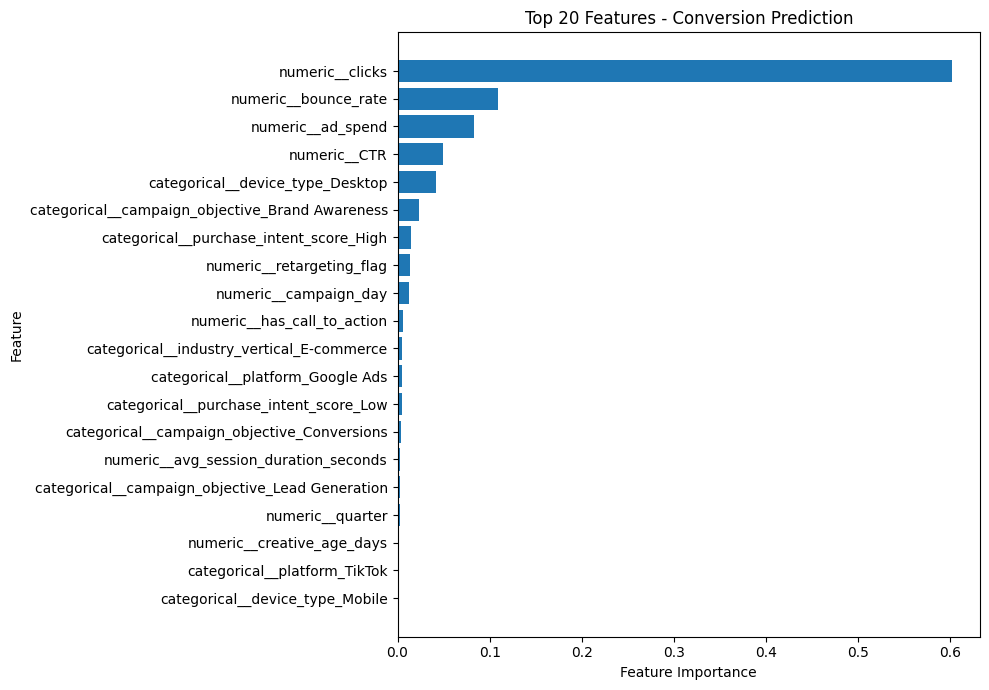

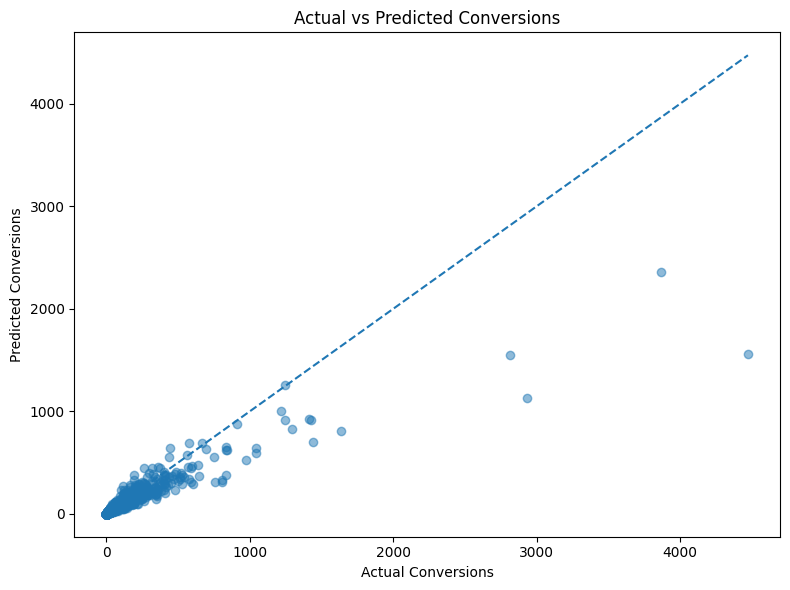


RESIDUAL ANALYSIS
Mean residual   : 12.3545
Minimum residual: -198.6049
Maximum residual: 2911.0928
Residual std    : 103.0235


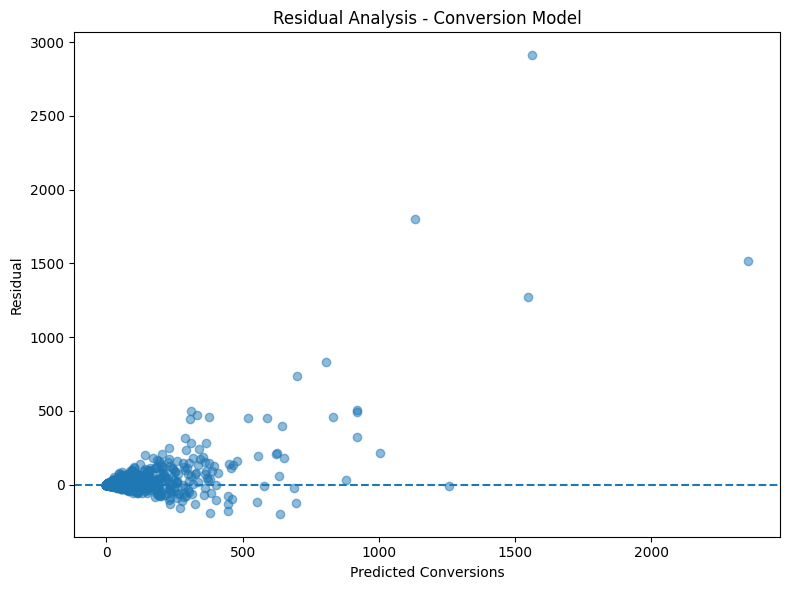


✅ Feature importance saved: conversion_feature_importance.csv

✅ CONVERSION MODEL EVALUATION COMPLETED


In [ ]:
# ============================================================
# STEP 7 - CONVERSION MODEL EVALUATION
# AI MARKETING CAMPAIGN OPTIMIZATION
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("=" * 70)
print("CONVERSION PREDICTION - MODEL EVALUATION")
print("=" * 70)


# ============================================================
# 1. CALCULATE FINAL METRICS
# ============================================================

final_mae = mean_absolute_error(
    y_test,
    y_pred
)

final_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        y_pred
    )
)

final_r2 = r2_score(
    y_test,
    y_pred
)


# ============================================================
# 2. PRINT FINAL METRICS
# ============================================================

print("\n" + "=" * 70)
print("FINAL CONVERSION MODEL PERFORMANCE")
print("=" * 70)

print(
    f"Model : Gradient Boosting Regressor"
)

print(
    f"MAE   : {final_mae:.4f}"
)

print(
    f"RMSE  : {final_rmse:.4f}"
)

print(
    f"R²    : {final_r2:.4f}"
)


# ============================================================
# 3. FEATURE IMPORTANCE
# ============================================================

print("\n" + "=" * 70)
print("FEATURE IMPORTANCE")
print("=" * 70)

feature_importance = pd.DataFrame({
    "feature": feature_names,
    "importance": conversion_model.feature_importances_
})

feature_importance = (
    feature_importance
    .sort_values(
        by="importance",
        ascending=False
    )
    .reset_index(drop=True)
)

print("\nTop 20 features:")

print(
    feature_importance
    .head(20)
    .to_string(index=False)
)


# ============================================================
# 4. PLOT TOP 20 FEATURES
# ============================================================

top_features = (
    feature_importance
    .head(20)
    .sort_values(
        by="importance"
    )
)

plt.figure(
    figsize=(10, 7)
)

plt.barh(
    top_features["feature"],
    top_features["importance"]
)

plt.xlabel(
    "Feature Importance"
)

plt.ylabel(
    "Feature"
)

plt.title(
    "Top 20 Features - Conversion Prediction"
)

plt.tight_layout()

plt.show()


# ============================================================
# 5. ACTUAL VS PREDICTED
# ============================================================

plt.figure(
    figsize=(8, 6)
)

plt.scatter(
    y_test,
    y_pred,
    alpha=0.5
)

# Perfect prediction line
max_value = max(
    y_test.max(),
    y_pred.max()
)

plt.plot(
    [0, max_value],
    [0, max_value],
    linestyle="--"
)

plt.xlabel(
    "Actual Conversions"
)

plt.ylabel(
    "Predicted Conversions"
)

plt.title(
    "Actual vs Predicted Conversions"
)

plt.tight_layout()

plt.show()


# ============================================================
# 6. RESIDUAL ANALYSIS
# ============================================================

residuals = (
    y_test.values - y_pred
)

print("\n" + "=" * 70)
print("RESIDUAL ANALYSIS")
print("=" * 70)

print(
    f"Mean residual   : {residuals.mean():.4f}"
)

print(
    f"Minimum residual: {residuals.min():.4f}"
)

print(
    f"Maximum residual: {residuals.max():.4f}"
)

print(
    f"Residual std    : {residuals.std():.4f}"
)


# ============================================================
# 7. RESIDUAL PLOT
# ============================================================

plt.figure(
    figsize=(8, 6)
)

plt.scatter(
    y_pred,
    residuals,
    alpha=0.5
)

plt.axhline(
    y=0,
    linestyle="--"
)

plt.xlabel(
    "Predicted Conversions"
)

plt.ylabel(
    "Residual"
)

plt.title(
    "Residual Analysis - Conversion Model"
)

plt.tight_layout()

plt.show()


# ============================================================
# 8. SAVE FEATURE IMPORTANCE
# ============================================================

FEATURE_IMPORTANCE_PATH = (
    "conversion_feature_importance.csv"
)

feature_importance.to_csv(
    FEATURE_IMPORTANCE_PATH,
    index=False
)

print(
    f"\n✅ Feature importance saved: "
    f"{FEATURE_IMPORTANCE_PATH}"
)


# ============================================================
# 9. FINAL STATUS
# ============================================================

print("\n" + "=" * 70)
print("✅ CONVERSION MODEL EVALUATION COMPLETED")
print("=" * 70)

In [ ]:
# ============================================================
# STEP 8 - SAVE CONVERSION MODEL ARTIFACTS
# AI MARKETING CAMPAIGN OPTIMIZATION
# ============================================================

import os
import joblib
import json
from pathlib import Path
from datetime import datetime


print("=" * 70)
print("CONVERSION PREDICTION - SAVING MODEL")
print("=" * 70)


# ============================================================
# 1. PROJECT PATH
# ============================================================

PROJECT_ROOT = Path(
    "/content/AI-Marketing-Campaign-Optimization/"
    "AI-Marketing-Campaign-Optimization-member2-revenue-conversion"
)

MODELS_DIR = PROJECT_ROOT / "models"

MODELS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print("\nProject root:")
print(PROJECT_ROOT)

print("\nModels directory:")
print(MODELS_DIR)


# ============================================================
# 2. MODEL PATHS
# ============================================================

CONVERSION_MODEL_PATH = (
    MODELS_DIR / "conversion_model.pkl"
)

CONVERSION_PREPROCESSOR_PATH = (
    MODELS_DIR / "conversion_preprocessor.pkl"
)

CONVERSION_INFO_PATH = (
    MODELS_DIR / "conversion_model_info.pkl"
)


# ============================================================
# 3. SAVE MODEL
# ============================================================

print("\nSaving conversion model...")

joblib.dump(
    conversion_model,
    CONVERSION_MODEL_PATH
)

print(
    f"✅ Model saved: {CONVERSION_MODEL_PATH}"
)


# ============================================================
# 4. SAVE PREPROCESSOR
# ============================================================

print("\nSaving preprocessing pipeline...")

joblib.dump(
    preprocessor,
    CONVERSION_PREPROCESSOR_PATH
)

print(
    f"✅ Preprocessor saved: "
    f"{CONVERSION_PREPROCESSOR_PATH}"
)


# ============================================================
# 5. CREATE MODEL INFORMATION
# ============================================================

model_info = {
    "model_name": "GradientBoostingRegressor",
    "target": "conversions",
    "target_transformation": "log1p",
    "inverse_transformation": "expm1",

    "training_samples": int(len(X_train)),
    "testing_samples": int(len(X_test)),

    "original_features": int(X.shape[1]),
    "processed_features": int(
        X_train_processed.shape[1]
    ),

    "numeric_features": NUMERIC_FEATURES,
    "categorical_features": CATEGORICAL_FEATURES,

    "removed_columns": [
        "campaign_id",
        "conversions",
        "revenue",
        "conversion_rate",
        "CPA",
        "ROAS",
        "profit"
    ],

    "model_parameters": {
        "n_estimators": 250,
        "learning_rate": 0.05,
        "max_depth": 3,
        "min_samples_split": 10,
        "min_samples_leaf": 5,
        "subsample": 0.8,
        "loss": "huber",
        "random_state": 42
    },

    "metrics": {
        "MAE": float(final_mae),
        "RMSE": float(final_rmse),
        "R2": float(final_r2)
    },

    "target_statistics": {
        "mean": float(y.mean()),
        "median": float(y.median()),
        "minimum": float(y.min()),
        "maximum": float(y.max()),
        "zero_conversion_campaigns": int(
            (y == 0).sum()
        )
    },

    "created_at": datetime.now().isoformat()
}


# ============================================================
# 6. SAVE MODEL INFORMATION
# ============================================================

joblib.dump(
    model_info,
    CONVERSION_INFO_PATH
)

print(
    f"✅ Model information saved: "
    f"{CONVERSION_INFO_PATH}"
)


# ============================================================
# 7. VERIFY FILES
# ============================================================

print("\n" + "=" * 70)
print("VERIFYING SAVED ARTIFACTS")
print("=" * 70)

files_to_check = [
    CONVERSION_MODEL_PATH,
    CONVERSION_PREPROCESSOR_PATH,
    CONVERSION_INFO_PATH
]

all_files_exist = True

for file_path in files_to_check:

    if file_path.exists():

        size_kb = (
            file_path.stat().st_size
            / 1024
        )

        print(
            f" ✅ {file_path.name}"
            f" ({size_kb:.2f} KB)"
        )

    else:

        print(
            f" ❌ {file_path.name} NOT FOUND"
        )

        all_files_exist = False


# ============================================================
# 8. PRINT MODEL SUMMARY
# ============================================================

print("\n" + "=" * 70)
print("CONVERSION MODEL SUMMARY")
print("=" * 70)

print(
    f"Model       : "
    f"{model_info['model_name']}"
)

print(
    f"Target      : "
    f"{model_info['target']}"
)

print(
    f"Transformation: "
    f"{model_info['target_transformation']}"
)

print(
    f"MAE         : "
    f"{final_mae:.4f}"
)

print(
    f"RMSE        : "
    f"{final_rmse:.4f}"
)

print(
    f"R²          : "
    f"{final_r2:.4f}"
)

print(
    f"Features     : "
    f"{X.shape[1]} → {X_train_processed.shape[1]}"
)


# ============================================================
# 9. FINAL STATUS
# ============================================================

if all_files_exist:

    print("\n" + "=" * 70)
    print("✅ CONVERSION MODEL ARTIFACTS SAVED SUCCESSFULLY")
    print("=" * 70)

    print("\nFiles ready for backend integration:")

    for file_path in files_to_check:
        print(
            f" - models/{file_path.name}"
        )

else:

    raise FileNotFoundError(
        "❌ One or more model artifacts "
        "were not saved correctly."
    )

CONVERSION PREDICTION - SAVING MODEL

Project root:
/content/AI-Marketing-Campaign-Optimization/AI-Marketing-Campaign-Optimization-member2-revenue-conversion

Models directory:
/content/AI-Marketing-Campaign-Optimization/AI-Marketing-Campaign-Optimization-member2-revenue-conversion/models

Saving conversion model...
✅ Model saved: /content/AI-Marketing-Campaign-Optimization/AI-Marketing-Campaign-Optimization-member2-revenue-conversion/models/conversion_model.pkl

Saving preprocessing pipeline...
✅ Preprocessor saved: /content/AI-Marketing-Campaign-Optimization/AI-Marketing-Campaign-Optimization-member2-revenue-conversion/models/conversion_preprocessor.pkl
✅ Model information saved: /content/AI-Marketing-Campaign-Optimization/AI-Marketing-Campaign-Optimization-member2-revenue-conversion/models/conversion_model_info.pkl

VERIFYING SAVED ARTIFACTS
 ✅ conversion_model.pkl (333.40 KB)
 ✅ conversion_preprocessor.pkl (9.65 KB)
 ✅ conversion_model_info.pkl (1.33 KB)

CONVERSION MODEL SUMMARY
M

In [ ]:
# ============================================================
# STEP 9 - CREATE CONVERSION PREDICTOR MODULE
# AI MARKETING CAMPAIGN OPTIMIZATION
# ============================================================

from pathlib import Path
import joblib
import pandas as pd
import numpy as np


# ============================================================
# PATHS
# ============================================================

PROJECT_ROOT = Path(
    "/content/AI-Marketing-Campaign-Optimization/"
    "AI-Marketing-Campaign-Optimization-member2-revenue-conversion"
)

MODELS_DIR = PROJECT_ROOT / "models"

MODEL_PATH = MODELS_DIR / "conversion_model.pkl"
PREPROCESSOR_PATH = MODELS_DIR / "conversion_preprocessor.pkl"


# ============================================================
# EXPECTED INPUT FEATURES
# ============================================================

EXPECTED_FEATURES = [
    "campaign_objective",
    "platform",
    "ad_placement",
    "device_type",
    "operating_system",
    "creative_format",
    "creative_size",
    "ad_copy_length",
    "has_call_to_action",
    "creative_emotion",
    "creative_age_days",
    "target_audience_age",
    "target_audience_gender",
    "audience_interest_category",
    "income_bracket",
    "purchase_intent_score",
    "retargeting_flag",
    "start_date",
    "quarter",
    "day_of_week",
    "hour_of_day",
    "campaign_day",
    "quality_score",
    "actual_cpc",
    "impressions",
    "clicks",
    "ad_spend",
    "bounce_rate",
    "avg_session_duration_seconds",
    "pages_per_session",
    "industry_vertical",
    "budget_tier",
    "CTR",
    "CPC"
]


# ============================================================
# LOAD MODEL
# ============================================================

if not MODEL_PATH.exists():

    raise FileNotFoundError(
        f"Conversion model not found: {MODEL_PATH}"
    )


if not PREPROCESSOR_PATH.exists():

    raise FileNotFoundError(
        f"Conversion preprocessor not found: "
        f"{PREPROCESSOR_PATH}"
    )


model = joblib.load(
    MODEL_PATH
)

preprocessor = joblib.load(
    PREPROCESSOR_PATH
)


# ============================================================
# PREPARE INPUT
# ============================================================

def prepare_input(campaign_data: dict) -> pd.DataFrame:
    """
    Prepare campaign data for conversion prediction.

    The preprocessing must match the pipeline used
    during model training.
    """

    if not isinstance(campaign_data, dict):

        raise TypeError(
            "campaign_data must be a dictionary."
        )


    # --------------------------------------------------------
    # Create dataframe
    # --------------------------------------------------------

    input_df = pd.DataFrame(
        [campaign_data]
    )


    # --------------------------------------------------------
    # Check required input columns
    # --------------------------------------------------------

    missing_features = [
        feature
        for feature in EXPECTED_FEATURES
        if feature not in input_df.columns
    ]

    if missing_features:

        raise ValueError(
            "Missing required campaign features: "
            + ", ".join(missing_features)
        )


    # --------------------------------------------------------
    # Keep only expected features
    # --------------------------------------------------------

    input_df = input_df[
        EXPECTED_FEATURES
    ].copy()


    # --------------------------------------------------------
    # Date feature engineering
    # --------------------------------------------------------

    input_df["start_date"] = pd.to_datetime(
        input_df["start_date"],
        errors="coerce"
    )


    if input_df["start_date"].isna().any():

        raise ValueError(
            "Invalid start_date. "
            "Use format YYYY-MM-DD."
        )


    input_df["start_year"] = (
        input_df["start_date"].dt.year
    )

    input_df["start_month"] = (
        input_df["start_date"].dt.month
    )

    input_df["start_day"] = (
        input_df["start_date"].dt.day
    )


    # Remove original date column
    input_df = input_df.drop(
        columns=["start_date"]
    )


    # --------------------------------------------------------
    # Convert boolean values
    # --------------------------------------------------------

    for column in [
        "has_call_to_action",
        "retargeting_flag"
    ]:

        value = input_df[column].iloc[0]

        if isinstance(value, str):

            value_lower = value.strip().lower()

            if value_lower in [
                "true",
                "1",
                "yes"
            ]:

                input_df[column] = 1

            elif value_lower in [
                "false",
                "0",
                "no"
            ]:

                input_df[column] = 0

            else:

                raise ValueError(
                    f"Invalid boolean value for "
                    f"{column}: {value}"
                )

        else:

            input_df[column] = (
                input_df[column]
                .astype(int)
            )


    # --------------------------------------------------------
    # Numeric validation
    # --------------------------------------------------------

    NUMERIC_COLUMNS = [
        "creative_age_days",
        "quarter",
        "hour_of_day",
        "campaign_day",
        "quality_score",
        "actual_cpc",
        "impressions",
        "clicks",
        "ad_spend",
        "bounce_rate",
        "avg_session_duration_seconds",
        "pages_per_session",
        "CTR",
        "CPC"
    ]


    for column in NUMERIC_COLUMNS:

        input_df[column] = pd.to_numeric(
            input_df[column],
            errors="coerce"
        )


    invalid_numeric = [
        column
        for column in NUMERIC_COLUMNS
        if pd.isna(
            input_df[column].iloc[0]
        )
    ]


    if invalid_numeric:

        raise ValueError(
            "Invalid numeric values found in: "
            + ", ".join(invalid_numeric)
        )


    # --------------------------------------------------------
    # Add date features
    # --------------------------------------------------------

    # The trained preprocessor expects these columns.
    # They were created during Step 4.

    final_columns = [
        "campaign_objective",
        "platform",
        "ad_placement",
        "device_type",
        "operating_system",
        "creative_format",
        "creative_size",
        "ad_copy_length",
        "has_call_to_action",
        "creative_emotion",
        "creative_age_days",
        "target_audience_age",
        "target_audience_gender",
        "audience_interest_category",
        "income_bracket",
        "purchase_intent_score",
        "retargeting_flag",
        "quarter",
        "day_of_week",
        "hour_of_day",
        "campaign_day",
        "quality_score",
        "actual_cpc",
        "impressions",
        "clicks",
        "ad_spend",
        "bounce_rate",
        "avg_session_duration_seconds",
        "pages_per_session",
        "industry_vertical",
        "budget_tier",
        "CTR",
        "CPC",
        "start_year",
        "start_month",
        "start_day"
    ]


    input_df = input_df[
        final_columns
    ]


    return input_df


# ============================================================
# PREDICT CONVERSIONS
# ============================================================

def predict_conversions(
    campaign_data: dict
) -> float:

    """
    Predict the number of conversions
    for a marketing campaign.

    Parameters
    ----------
    campaign_data : dict
        Campaign feature values.

    Returns
    -------
    float
        Predicted conversion count.
    """

    # Prepare input
    input_df = prepare_input(
        campaign_data
    )


    # Transform using trained preprocessor
    processed_input = (
        preprocessor.transform(
            input_df
        )
    )


    # Predict log-transformed value
    prediction_log = model.predict(
        processed_input
    )[0]


    # Reverse log1p transformation
    prediction = np.expm1(
        prediction_log
    )


    # Conversion count cannot be negative
    prediction = max(
        0.0,
        float(prediction)
    )


    return prediction


# ============================================================
# MODULE TEST
# ============================================================

if __name__ == "__main__":

    print("=" * 70)
    print("CONVERSION PREDICTOR MODULE")
    print("=" * 70)

    print(
        f"Model: {MODEL_PATH}"
    )

    print(
        f"Preprocessor: {PREPROCESSOR_PATH}"
    )

    print(
        f"Model type: "
        f"{type(model).__name__}"
    )

    print(
        f"Preprocessor type: "
        f"{type(preprocessor).__name__}"
    )

    print(
        "\n✅ Conversion predictor module loaded successfully."
    )

CONVERSION PREDICTOR MODULE
Model: /content/AI-Marketing-Campaign-Optimization/AI-Marketing-Campaign-Optimization-member2-revenue-conversion/models/conversion_model.pkl
Preprocessor: /content/AI-Marketing-Campaign-Optimization/AI-Marketing-Campaign-Optimization-member2-revenue-conversion/models/conversion_preprocessor.pkl
Model type: GradientBoostingRegressor
Preprocessor type: ColumnTransformer

✅ Conversion predictor module loaded successfully.


In [ ]:
# ============================================================
# STEP 10 - TEST CONVERSION PREDICTION
# ============================================================

test_campaign = {
    "campaign_objective": "Conversions",
    "platform": "Facebook",
    "ad_placement": "Feed",
    "device_type": "Mobile",
    "operating_system": "Android",
    "creative_format": "Image",
    "creative_size": "1080x1080",
    "ad_copy_length": "Short",
    "has_call_to_action": True,
    "creative_emotion": "Trust",
    "creative_age_days": 10,
    "target_audience_age": "25-34",
    "target_audience_gender": "All",
    "audience_interest_category": "Tech Enthusiasts",
    "income_bracket": "$50K-$100K",
    "purchase_intent_score": "High",
    "retargeting_flag": True,
    "start_date": "2025-06-15",
    "quarter": 2,
    "day_of_week": "Sunday",
    "hour_of_day": 14,
    "campaign_day": 7,
    "quality_score": 8,
    "actual_cpc": 2.50,
    "impressions": 10000,
    "clicks": 500,
    "ad_spend": 1250.0,
    "bounce_rate": 0.35,
    "avg_session_duration_seconds": 120,
    "pages_per_session": 3.5,
    "industry_vertical": "E-commerce",
    "budget_tier": "Medium",
    "CTR": 0.05,
    "CPC": 2.50
}


print("=" * 70)
print("CONVERSION PREDICTION TEST")
print("=" * 70)

try:

    prediction = predict_conversions(test_campaign)

    print(f"\nPredicted conversions: {prediction:.2f}")

    print("\n✅ CONVERSION PREDICTION SUCCESSFUL")

except Exception as e:

    print("\n❌ PREDICTION FAILED")
    print(f"Error: {type(e).__name__}: {e}")

    raise

CONVERSION PREDICTION TEST

Predicted conversions: 24.61

✅ CONVERSION PREDICTION SUCCESSFUL


In [ ]:
# ============================================================
# STEP 11 - CREATE PRODUCTION CONVERSION PREDICTOR
# ============================================================

from pathlib import Path
import joblib
import pandas as pd
import numpy as np


# ------------------------------------------------------------
# PROJECT PATH
# ------------------------------------------------------------

PROJECT_ROOT = Path(
    "/content/AI-Marketing-Campaign-Optimization/"
    "AI-Marketing-Campaign-Optimization-member2-revenue-conversion"
)

MODEL_PATH = PROJECT_ROOT / "models" / "conversion_model.pkl"
PREPROCESSOR_PATH = PROJECT_ROOT / "models" / "conversion_preprocessor.pkl"


# ------------------------------------------------------------
# LOAD ARTIFACTS
# ------------------------------------------------------------

conversion_model = joblib.load(MODEL_PATH)
conversion_preprocessor = joblib.load(PREPROCESSOR_PATH)


# ------------------------------------------------------------
# FEATURES USED DURING TRAINING
# ------------------------------------------------------------

NUMERIC_FEATURES = [
    "has_call_to_action",
    "creative_age_days",
    "retargeting_flag",
    "quarter",
    "hour_of_day",
    "campaign_day",
    "quality_score",
    "actual_cpc",
    "impressions",
    "clicks",
    "ad_spend",
    "bounce_rate",
    "avg_session_duration_seconds",
    "pages_per_session",
    "CTR",
    "CPC",
    "start_year",
    "start_month",
    "start_day",
]


CATEGORICAL_FEATURES = [
    "campaign_objective",
    "platform",
    "ad_placement",
    "device_type",
    "operating_system",
    "creative_format",
    "creative_size",
    "ad_copy_length",
    "creative_emotion",
    "target_audience_age",
    "target_audience_gender",
    "audience_interest_category",
    "income_bracket",
    "purchase_intent_score",
    "day_of_week",
    "industry_vertical",
    "budget_tier",
]


EXPECTED_FEATURES = (
    NUMERIC_FEATURES +
    CATEGORICAL_FEATURES
)


# ------------------------------------------------------------
# INPUT PREPARATION
# ------------------------------------------------------------

def prepare_conversion_input(campaign_data: dict) -> pd.DataFrame:
    """
    Prepare campaign input exactly as required
    by the trained conversion preprocessing pipeline.
    """

    data = campaign_data.copy()

    # --------------------------------------------
    # Date processing
    # --------------------------------------------

    if "start_date" in data:

        date_value = pd.to_datetime(
            data["start_date"],
            errors="coerce"
        )

        data["start_year"] = date_value.year
        data["start_month"] = date_value.month
        data["start_day"] = date_value.day

        del data["start_date"]


    # --------------------------------------------
    # Boolean conversion
    # --------------------------------------------

    for column in [
        "has_call_to_action",
        "retargeting_flag"
    ]:

        if column in data:

            data[column] = int(
                bool(data[column])
            )


    # --------------------------------------------
    # Create dataframe
    # --------------------------------------------

    input_df = pd.DataFrame([data])


    # --------------------------------------------
    # Validate required features
    # --------------------------------------------

    missing = [
        feature
        for feature in EXPECTED_FEATURES
        if feature not in input_df.columns
    ]

    if missing:

        raise ValueError(
            "Missing required conversion features: "
            + ", ".join(missing)
        )


    # --------------------------------------------
    # Keep exact training order
    # --------------------------------------------

    input_df = input_df[
        EXPECTED_FEATURES
    ]


    return input_df


# ------------------------------------------------------------
# PREDICTION FUNCTION
# ------------------------------------------------------------

def predict_conversions(campaign_data: dict) -> float:
    """
    Predict the number of conversions for a campaign.

    Returns
    -------
    float
        Predicted conversion count.
    """

    input_df = prepare_conversion_input(
        campaign_data
    )


    # Preprocess

    processed_input = conversion_preprocessor.transform(
        input_df
    )


    # Model prediction

    log_prediction = conversion_model.predict(
        processed_input
    )[0]


    # Reverse log1p transformation

    prediction = np.expm1(
        log_prediction
    )


    # Conversion count cannot be negative

    prediction = max(
        0.0,
        float(prediction)
    )


    return prediction


# ------------------------------------------------------------
# MODULE TEST
# ------------------------------------------------------------

print("=" * 70)
print("CONVERSION PREDICTOR MODULE")
print("=" * 70)

print(f"Model       : {MODEL_PATH}")
print(f"Preprocessor: {PREPROCESSOR_PATH}")
print(f"Model type  : {type(conversion_model).__name__}")
print(
    f"Features    : {len(EXPECTED_FEATURES)}"
)

print("\n✅ Conversion predictor module created successfully.")

CONVERSION PREDICTOR MODULE
Model       : /content/AI-Marketing-Campaign-Optimization/AI-Marketing-Campaign-Optimization-member2-revenue-conversion/models/conversion_model.pkl
Preprocessor: /content/AI-Marketing-Campaign-Optimization/AI-Marketing-Campaign-Optimization-member2-revenue-conversion/models/conversion_preprocessor.pkl
Model type  : GradientBoostingRegressor
Features    : 36

✅ Conversion predictor module created successfully.


In [ ]:
# ============================================================
# STEP 12 - FINAL PRODUCTION PREDICTION TEST
# ============================================================

test_campaign = {
    "campaign_objective": "Conversions",
    "platform": "Facebook",
    "ad_placement": "Feed",
    "device_type": "Mobile",
    "operating_system": "Android",
    "creative_format": "Image",
    "creative_size": "1080x1080",
    "ad_copy_length": "Short",
    "has_call_to_action": True,
    "creative_emotion": "Trust",
    "creative_age_days": 10,
    "target_audience_age": "25-34",
    "target_audience_gender": "All",
    "audience_interest_category": "Tech Enthusiasts",
    "income_bracket": "$50K-$100K",
    "purchase_intent_score": "High",
    "retargeting_flag": True,
    "start_date": "2025-06-15",
    "quarter": 2,
    "day_of_week": "Sunday",
    "hour_of_day": 14,
    "campaign_day": 7,
    "quality_score": 8,
    "actual_cpc": 2.50,
    "impressions": 10000,
    "clicks": 500,
    "ad_spend": 1250.0,
    "bounce_rate": 0.35,
    "avg_session_duration_seconds": 120,
    "pages_per_session": 3.5,
    "industry_vertical": "E-commerce",
    "budget_tier": "Medium",
    "CTR": 0.05,
    "CPC": 2.50
}

print("=" * 70)
print("FINAL CONVERSION PREDICTOR TEST")
print("=" * 70)

try:
    predicted_conversions = predict_conversions(test_campaign)

    print(f"\nPredicted conversions: {predicted_conversions:.2f}")

    if predicted_conversions >= 0:
        print("\n" + "=" * 70)
        print("✅ FINAL CONVERSION PREDICTOR TEST PASSED")
        print("=" * 70)

except Exception as e:
    print("\n" + "=" * 70)
    print("❌ FINAL CONVERSION PREDICTOR TEST FAILED")
    print("=" * 70)
    print(f"\nError: {type(e).__name__}: {e}")
    raise

FINAL CONVERSION PREDICTOR TEST

Predicted conversions: 24.61

✅ FINAL CONVERSION PREDICTOR TEST PASSED


In [ ]:
from google.colab import files
from pathlib import Path

# Project models directory
models_dir = Path(
    "/content/AI-Marketing-Campaign-Optimization/"
    "AI-Marketing-Campaign-Optimization-member2-revenue-conversion/"
    "models"
)

# Files to download
model_files = [
    models_dir / "conversion_model.pkl",
    models_dir / "conversion_preprocessor.pkl",
    models_dir / "conversion_model_info.pkl"
]

print("=" * 70)
print("DOWNLOADING CONVERSION MODEL FILES")
print("=" * 70)

for file_path in model_files:

    if not file_path.exists():
        print(f"❌ File not found: {file_path}")
        continue

    print(f"✅ Found: {file_path.name}")

print("\nStarting downloads...")

# Download each file
for file_path in model_files:

    if file_path.exists():
        files.download(str(file_path))

print("\n" + "=" * 70)
print("✅ DOWNLOAD REQUESTS SENT")
print("=" * 70)

print("""
Files:
1. conversion_model.pkl
2. conversion_preprocessor.pkl
3. conversion_model_info.pkl

Check your browser Downloads folder.
""")

DOWNLOADING CONVERSION MODEL FILES
✅ Found: conversion_model.pkl
✅ Found: conversion_preprocessor.pkl
✅ Found: conversion_model_info.pkl

Starting downloads...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


✅ DOWNLOAD REQUESTS SENT

Files:
1. conversion_model.pkl
2. conversion_preprocessor.pkl
3. conversion_model_info.pkl

Check your browser Downloads folder.



In [ ]:
print(X_train_processed.shape)
print(len(feature_names))

NameError: name 'X_train_processed' is not defined